# Experimentos de clustering

Busqueda sistematica de la mejor segmentacion. Se combinan conjuntos de variables
(conducta electoral, trayectoria, PJ 2025, demografia, region), preprocesamientos y
algoritmos con sus hiperparametros. El objetivo es descartar con evidencia las
alternativas debiles y quedarse con pocas candidatas solidas.

Tres etapas:
1. **Busqueda en malla** sobre una muestra ponderada por lista nominal.
2. **Estabilidad** por bootstrap de las mejores configuraciones.
3. **Afinacion** de las finalistas con todos los datos y comparacion contra el modelo
   del notebook 04 (que no se modifica).

## 1. Configuracion

In [1]:
import copy
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.stats import chi2_contingency
from sklearn.cluster import HDBSCAN, Birch, BisectingKMeans, KMeans
from sklearn.decomposition import PCA
from sklearn.manifold import SpectralEmbedding
from sklearn.metrics import (
    adjusted_rand_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    silhouette_score,
)
from sklearn.mixture import GaussianMixture
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 120, "figure.facecolor": "white"})

## 2. Parametros y rutas

In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

DIR_PREPROCESSED = ROOT / "DATA" / "PREPROCESSED"

ELECCIONES = ["P2009", "P2012", "P2015", "P2018", "P2021", "P2024"]
CORTES_EDAD = [17, 24, 29, 39, 49, 59, 69, 79, 200]
ETIQUETAS_EDAD = ["18-24", "25-29", "30-39", "40-49", "50-59", "60-69", "70-79", "80+"]
REGIONES = ["Noroeste", "Noreste", "Occidente", "Centro", "Sur-Sureste"]

K_RANGE = range(3, 9)
K_VALIDO = range(4, 7)  # convocatoria pide 4-6 perfiles
MIN_PCT_PERFIL = 5.0
MAX_PCT_RUIDO = 10.0

N_FIT = 60_000
N_SUB = 8_000
N_EVAL = 10_000
N_SIL = 5_000
N_FINAL = 200_000
N_BOOT = 5
N_CANDIDATOS = 15
N_FINALISTAS = 3
ARI_ESTABLE = 0.8
RANDOM_STATE = 42

## 3. Carga de datos

### 3.1 Celdas con historial

Celdas seccion x sexo x grupo de edad generadas en el notebook 03.

In [3]:
celdas = pd.read_parquet(DIR_PREPROCESSED / "celdas_historial.parquet")
celdas["GRUPO_EDAD"] = celdas["GRUPO_EDAD"].astype(str)
print(f"Celdas: {len(celdas):,}")

Celdas: 657,497


### 3.2 Peso poblacional

Mismo criterio que el notebook 04: votantes potenciales 2024 (SV + NV) por celda.

In [4]:
fed24 = pd.read_parquet(
    DIR_PREPROCESSED / "conteos_federal_2009_2024.parquet",
    columns=["EDOCVE", "SECCION", "SEXO", "EDAD", "AELEC", "SV", "NV"],
    filters=[("AELEC", "==", 2024)],
)
fed24["GRUPO_EDAD"] = pd.cut(fed24["EDAD"], bins=CORTES_EDAD, labels=ETIQUETAS_EDAD)
fed24["VOTANTES"] = fed24["SV"] + fed24["NV"]

pesos = (
    fed24.groupby(["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"], observed=True)["VOTANTES"]
    .sum()
    .reset_index()
    .rename(columns={"VOTANTES": "peso"})
)
pesos["GRUPO_EDAD"] = pesos["GRUPO_EDAD"].astype(str)
del fed24

celdas = celdas.merge(pesos, on=["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD"], how="left")
print(f"Peso total: {celdas['peso'].sum():,.0f} personas")

Peso total: 71,203,577 personas


### 3.3 Participacion PJ 2025 y casos completos

Para que todas las configuraciones se comparen sobre la misma poblacion,
se conservan solo las celdas con peso y con tasa PJ 2025.

In [5]:
secciones = pd.read_parquet(
    DIR_PREPROCESSED / "secciones_historial.parquet", columns=["EDOCVE", "SECCION", "P_PJ2025"]
)
celdas = celdas.merge(secciones, on=["EDOCVE", "SECCION"], how="left")
del secciones

n0, w0 = len(celdas), celdas["peso"].sum()
celdas = celdas.dropna(subset=["peso", "P_PJ2025"]).reset_index(drop=True)
print(f"Celdas completas: {len(celdas):,} de {n0:,} ({celdas['peso'].sum() / w0 * 100:.1f}% del peso)")

Celdas completas: 644,887 de 657,497 (96.4% del peso)


### 3.4 Codificacion de variables demograficas

Edad y tipo de seccion como ordinales, sexo como indicador de mujer y region como dummies.

In [6]:
celdas["EDAD_ORD"] = celdas["GRUPO_EDAD"].map({g: i for i, g in enumerate(ETIQUETAS_EDAD)})
celdas["MUJER"] = (celdas["SEXO"] == 1).astype(int)
celdas["TIPOSEC_ORD"] = celdas["TIPOSEC"].astype(str).map({"U": 0, "M": 1, "R": 2})
for r in REGIONES:
    celdas[f"REG_{r}"] = (celdas["REGION"] == r).astype(int)

print(celdas[["EDAD_ORD", "MUJER", "TIPOSEC_ORD"]].isna().sum().to_dict())

{'EDAD_ORD': 0, 'MUJER': 0, 'TIPOSEC_ORD': 0}


## 4. Diseno del experimento

### 4.1 Conjuntos de variables

- **A-D:** solo conducta electoral (indicadores o trayectoria completa, con y sin PJ 2025).
- **E-H:** conducta mas demografia (edad, sexo, tipo de seccion) y region.
- **I:** solo demografia y region. Es un control: si gana, la conducta no aporta.

In [7]:
BASE = ["promedio", "brecha_pres", "tendencia"]
INDICADORES = BASE + ["desviacion", "P_PJ2025"]
TRAYECTORIA_PJ = ELECCIONES + ["P_PJ2025"]
DEMO = ["EDAD_ORD", "MUJER", "TIPOSEC_ORD"]
REG = [f"REG_{r}" for r in REGIONES]

CONJUNTOS = {
    "A_base": BASE,
    "B_indicadores": INDICADORES,
    "C_trayectoria": ELECCIONES,
    "D_trayectoria_pj": TRAYECTORIA_PJ,
    "E_base_demo": BASE + DEMO,
    "F_indicadores_demo": INDICADORES + DEMO,
    "G_trayectoria_demo": TRAYECTORIA_PJ + DEMO,
    "H_completo": TRAYECTORIA_PJ + DEMO + REG,
    "I_solo_demo": DEMO + REG,
}
for nombre, cols in CONJUNTOS.items():
    print(f"{nombre:20s} {len(cols):2d} variables")

A_base                3 variables
B_indicadores         5 variables
C_trayectoria         6 variables
D_trayectoria_pj      7 variables
E_base_demo           6 variables
F_indicadores_demo    8 variables
G_trayectoria_demo   10 variables
H_completo           15 variables
I_solo_demo           8 variables


### 4.2 Muestras ponderadas

Las muestras se extraen con probabilidad proporcional al peso, asi cada fila representa
aproximadamente el mismo numero de personas y las metricas sin ponderar equivalen a
metricas ponderadas. Esto permite usar algoritmos que no aceptan `sample_weight`.

- **eval** (10k): fija, se usa para calcular todas las metricas.
- **fit** (60k): ajuste de KMeans, BisectingKMeans y GMM.
- **sub** (8k, dentro de fit): ajuste de Birch, aglomerativo, espectral y HDBSCAN, que escalan
  mal. Los tres ultimos no tienen `predict`; sus etiquetas se extienden con KNN (k=5).

In [8]:
rng = np.random.default_rng(RANDOM_STATE)
p_all = celdas["peso"].to_numpy() / celdas["peso"].sum()
idx_eval = rng.choice(len(celdas), size=N_EVAL, replace=False, p=p_all)

resto = np.setdiff1d(np.arange(len(celdas)), idx_eval)
p_resto = p_all[resto] / p_all[resto].sum()


def muestra_ajuste(seed, n=N_FIT):
    idx = np.random.default_rng(seed).choice(resto, size=n, replace=False, p=p_resto)
    return idx, idx[:N_SUB]


idx_fit, idx_sub = muestra_ajuste(RANDOM_STATE)
print(f"eval={len(idx_eval):,}  fit={len(idx_fit):,}  sub={len(idx_sub):,}")

eval=10,000  fit=60,000  sub=8,000


### 4.3 Espacio de referencia comun

El silhouette de cada configuracion se calcula en su propio espacio, por lo que no es
comparable entre conjuntos de variables. Ademas, variables discretas como sexo inflan el
silhouette sin aportar perfiles de participacion. Por eso se calcula tambien un
**silhouette de referencia** en un espacio comun: las 6 tasas federales y PJ 2025 estandarizadas.

In [9]:
REF = ELECCIONES + ["P_PJ2025"]
ref_scaler = StandardScaler().fit(celdas.loc[idx_fit, REF])
X_ref = ref_scaler.transform(celdas.loc[idx_eval, REF])

prom_eval = celdas.loc[idx_eval, "promedio"].to_numpy()
edad_eval = celdas.loc[idx_eval, "GRUPO_EDAD"].to_numpy()
sexo_eval = celdas.loc[idx_eval, "SEXO"].to_numpy()
print(f"Espacio de referencia: {X_ref.shape}")

Espacio de referencia: (10000, 7)


### 4.4 Preprocesamiento

Estandar, robusto (mediana e IQR, menos sensible a extremos) y estandar + PCA
(90% de varianza; solo con mas de 3 variables).

In [10]:
PREPROCESOS = ["estandar", "robusto", "estandar_pca"]


def preprocesador(nombre):
    if nombre == "estandar":
        return StandardScaler()
    if nombre == "robusto":
        return RobustScaler()
    return make_pipeline(StandardScaler(), PCA(n_components=0.9, random_state=RANDOM_STATE))


def preparar(conjunto, prep, idx_ajuste):
    X = celdas[CONJUNTOS[conjunto]].to_numpy(dtype=float)
    tr = preprocesador(prep).fit(X[idx_ajuste])
    return tr, X


COMBOS = [
    (c, pre) for c, cols in CONJUNTOS.items() for pre in PREPROCESOS
    if not (pre == "estandar_pca" and len(cols) <= 3)
]
print(f"Combinaciones variables x preprocesamiento: {len(COMBOS)}")

Combinaciones variables x preprocesamiento: 26


### 4.5 Algoritmos e hiperparametros

| Algoritmo | Hiperparametros |
|---|---|
| KMeans | k |
| BisectingKMeans | k |
| Birch | k |
| GMM | k, tipo de covarianza (full, diag, tied, spherical) |
| Aglomerativo | k, enlace (ward, average, complete) |
| Espectral | k (embedding por vecinos cercanos + KMeans) |
| HDBSCAN | tamano minimo de cluster, min_samples, metodo de seleccion |

DBSCAN se omite porque HDBSCAN lo generaliza sin fijar `eps`. MeanShift y
AffinityPropagation se omiten por costo cuadratico y porque no controlan k.

In [11]:
def malla_algoritmos():
    malla = []
    for k in K_RANGE:
        malla += [("kmeans", {"k": k}), ("bisecting", {"k": k}),
                  ("birch", {"k": k}), ("espectral", {"k": k})]
        malla += [("gmm", {"k": k, "cov": cov}) for cov in ["full", "diag", "tied", "spherical"]]
        malla += [("aglomerativo", {"k": k, "link": l}) for l in ["ward", "average", "complete"]]
    for mcs in [80, 200, 400]:
        for ms in [5, 25]:
            for sel in ["eom", "leaf"]:
                malla.append(("hdbscan", {"mcs": mcs, "ms": ms, "sel": sel}))
    return malla


MALLA = malla_algoritmos()
print(f"Configuraciones por combinacion: {len(MALLA)}")
print(f"Total de configuraciones: {len(MALLA) * len(COMBOS):,}")

Configuraciones por combinacion: 78
Total de configuraciones: 2,028


Cada algoritmo devuelve un objeto con `predict`, para etiquetar cualquier conjunto de filas.
Los algoritmos sin `predict` (aglomerativo, espectral, HDBSCAN) se envuelven en un KNN.
El `cache` reutiliza el arbol de Birch, el arbol jerarquico y el embedding espectral entre valores de k.

In [12]:
def ajustar(algo, prm, Z_fit, Z_sub, seed, cache, w=None, n_init=None):
    extra = {}
    if algo == "kmeans":
        return KMeans(prm["k"], n_init=n_init or 4, random_state=seed).fit(Z_fit, sample_weight=w), extra
    if algo == "bisecting":
        m = BisectingKMeans(prm["k"], n_init=n_init or 2, random_state=seed)
        return m.fit(Z_fit, sample_weight=w), extra
    if algo == "birch":
        if "birch" not in cache:
            cache["birch"] = Birch(n_clusters=None, threshold=0.5).fit(Z_sub)
        m = copy.deepcopy(cache["birch"])
        m.set_params(n_clusters=prm["k"])
        return m.partial_fit(), extra
    if algo == "gmm":
        m = GaussianMixture(prm["k"], covariance_type=prm["cov"], n_init=n_init or 2,
                            random_state=seed).fit(Z_fit)
        extra["bic"] = m.bic(Z_fit)
        return m, extra

    if algo == "aglomerativo":
        if prm["link"] not in cache:
            cache[prm["link"]] = linkage(Z_sub, method=prm["link"])
        lab = fcluster(cache[prm["link"]], prm["k"], criterion="maxclust") - 1
    elif algo == "espectral":
        if "emb" not in cache:
            cache["emb"] = SpectralEmbedding(
                n_components=max(K_RANGE), affinity="nearest_neighbors",
                n_neighbors=15, random_state=seed,
            ).fit_transform(Z_sub)
        lab = KMeans(prm["k"], n_init=4, random_state=seed).fit_predict(cache["emb"][:, :prm["k"]])
    else:
        lab = HDBSCAN(min_cluster_size=prm["mcs"], min_samples=prm["ms"],
                      cluster_selection_method=prm["sel"]).fit_predict(Z_sub)
    return KNeighborsClassifier(n_neighbors=5).fit(Z_sub, lab), extra

### 4.6 Metricas

Todas sobre la muestra eval (ponderada por construccion). En HDBSCAN el ruido (etiqueta -1)
se excluye de las metricas y se reporta aparte.

- **sil, db, ch:** silhouette, Davies-Bouldin y Calinski-Harabasz en el espacio propio
  (los silhouette se calculan sobre una submuestra fija de 5k por costo).
- **sil_ref:** silhouette en el espacio de referencia comun.
- **r2_prom:** proporcion de la varianza del promedio de participacion explicada por los perfiles.
- **v_edad, v_sexo:** V de Cramer entre perfil y grupo de edad o sexo (informativas, no se usan para elegir).
- **min_pct, pct_ruido, k_eff:** tamano del perfil mas chico, ruido y numero efectivo de perfiles.

In [13]:
def cramers_v(a, b):
    tabla = pd.crosstab(a, b).to_numpy()
    if min(tabla.shape) < 2:
        return 0.0
    chi2 = chi2_contingency(tabla, correction=False)[0]
    return float(np.sqrt(chi2 / (tabla.sum() * (min(tabla.shape) - 1))))


def eta2(y, labels):
    medias = pd.Series(y).groupby(labels).transform("mean").to_numpy()
    return float(((medias - y.mean()) ** 2).sum() / ((y - y.mean()) ** 2).sum())


EN_SIL = np.zeros(N_EVAL, dtype=bool)
EN_SIL[np.random.default_rng(RANDOM_STATE).permutation(N_EVAL)[:N_SIL]] = True


def silhouette_seguro(Z, lab):
    return silhouette_score(Z, lab) if len(np.unique(lab)) > 1 else np.nan


def evaluar(labels, Z_eval):
    mask = labels >= 0
    m_sil = mask & EN_SIL
    lab = labels[mask]
    tamanos = pd.Series(lab).value_counts() / len(labels) * 100
    res = {"k_eff": len(tamanos), "pct_ruido": (1 - mask.mean()) * 100,
           "min_pct": tamanos.min() if len(tamanos) else 0.0}
    if len(tamanos) < 2:
        return res
    res.update({
        "sil": silhouette_seguro(Z_eval[m_sil], labels[m_sil]),
        "db": davies_bouldin_score(Z_eval[mask], lab),
        "ch": calinski_harabasz_score(Z_eval[mask], lab),
        "sil_ref": silhouette_seguro(X_ref[m_sil], labels[m_sil]),
        "r2_prom": eta2(prom_eval[mask], lab),
        "v_edad": cramers_v(lab, edad_eval[mask]),
        "v_sexo": cramers_v(lab, sexo_eval[mask]),
    })
    return res

## 5. Busqueda en malla (etapa 1)

Se recorre cada combinacion de variables y preprocesamiento con todas las configuraciones
de algoritmo. Se guardan metricas, tiempo y las etiquetas de la muestra eval.

In [14]:
CONFIGS = {}
ETIQUETAS = {}
registros = []
t_inicio = time.perf_counter()

for conjunto, prep in tqdm(COMBOS, desc="combinaciones"):
    tr, X = preparar(conjunto, prep, idx_fit)
    Z_fit, Z_eval = tr.transform(X[idx_fit]), tr.transform(X[idx_eval])
    Z_sub = Z_fit[:N_SUB]
    cache = {}
    for algo, prm in MALLA:
        cid = len(CONFIGS)
        CONFIGS[cid] = (conjunto, prep, algo, prm)
        t0 = time.perf_counter()
        modelo, extra = ajustar(algo, prm, Z_fit, Z_sub, RANDOM_STATE, cache)
        labels = modelo.predict(Z_eval)
        ETIQUETAS[cid] = labels
        registros.append({
            "id": cid, "conjunto": conjunto, "prep": prep, "algoritmo": algo,
            "params": ", ".join(f"{k}={v}" for k, v in prm.items()), "k": prm.get("k"),
            "dim": Z_fit.shape[1], **evaluar(labels, Z_eval), **extra,
            "seg": time.perf_counter() - t0,
        })

res = pd.DataFrame(registros)
print(f"{len(res):,} configuraciones en {(time.perf_counter() - t_inicio) / 60:.1f} min")

combinaciones:   0%|          | 0/26 [00:00<?, ?it/s]

2,028 configuraciones en 18.2 min


### 5.1 Filtro de validez y puntaje

Una configuracion es valida si produce 4-6 perfiles, ninguno menor al 5% de la poblacion,
y menos de 10% de ruido. Entre las validas, el puntaje es el promedio de los rangos
percentiles de `sil`, `sil_ref` y `r2_prom`: separacion propia, separacion en conducta
y capacidad de explicar el nivel de participacion.

In [15]:
def motivo(r):
    if r.k_eff not in K_VALIDO:
        return "k fuera de 4-6"
    if r.pct_ruido > MAX_PCT_RUIDO:
        return "ruido > 10%"
    if r.min_pct < MIN_PCT_PERFIL:
        return "perfil < 5%"
    return "valida"


res["motivo"] = res.apply(motivo, axis=1)
validas = res["motivo"] == "valida"
res["score"] = np.nan
res.loc[validas, "score"] = (
    res.loc[validas, ["sil", "sil_ref", "r2_prom"]].rank(pct=True).mean(axis=1)
)
print(f"Validas: {validas.sum():,} de {len(res):,}")

Validas: 521 de 2,028


### 5.2 Descartes por algoritmo

Configuraciones con k = 3, 7 u 8 se incluyen solo para ver la tendencia; siempre caen en
"k fuera de 4-6".

In [16]:
pd.crosstab(res["algoritmo"], res["motivo"], margins=True)

motivo,k fuera de 4-6,perfil < 5%,ruido > 10%,valida,All
algoritmo,,,,,
aglomerativo,245,141,0,82,468
birch,78,40,0,38,156
bisecting,78,21,0,57,156
espectral,78,29,0,49,156
gmm,310,103,0,211,624
hdbscan,253,3,21,35,312
kmeans,78,29,0,49,156
All,1120,366,21,521,2028


### 5.3 Mejor configuracion por algoritmo y conjunto de variables

Puntaje maximo entre configuraciones validas. Celdas vacias: ninguna configuracion valida.

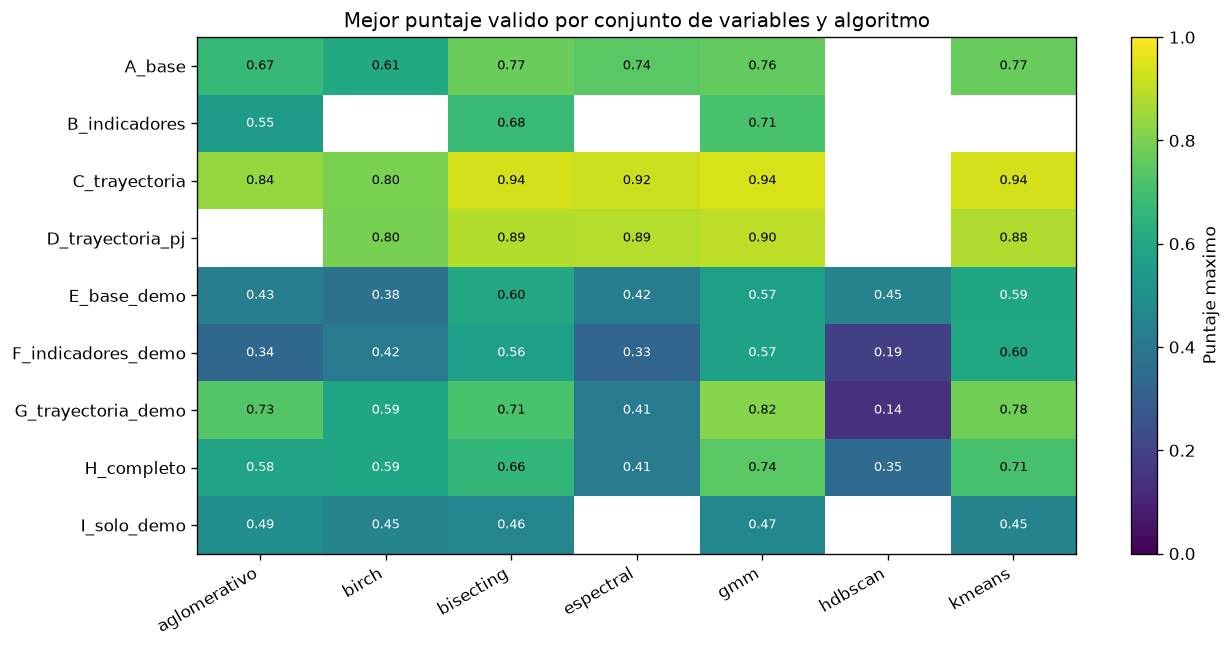

In [17]:
tabla = res.pivot_table(index="conjunto", columns="algoritmo", values="score", aggfunc="max")

fig, ax = plt.subplots(figsize=(11, 5.5))
im = ax.imshow(tabla.to_numpy(), cmap="viridis", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(tabla.shape[1]), tabla.columns, rotation=30, ha="right")
ax.set_yticks(range(tabla.shape[0]), tabla.index)
for i in range(tabla.shape[0]):
    for j in range(tabla.shape[1]):
        v = tabla.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                    color="white" if v < 0.6 else "black", fontsize=8)
fig.colorbar(im, ax=ax, label="Puntaje maximo")
ax.set_title("Mejor puntaje valido por conjunto de variables y algoritmo")
plt.tight_layout()
plt.show()

### 5.4 Separacion en conducta segun k

Silhouette de referencia maximo por algoritmo y k (todas las combinaciones de variables,
sin filtro de validez). Muestra si la estructura mejora o empeora al aumentar k.

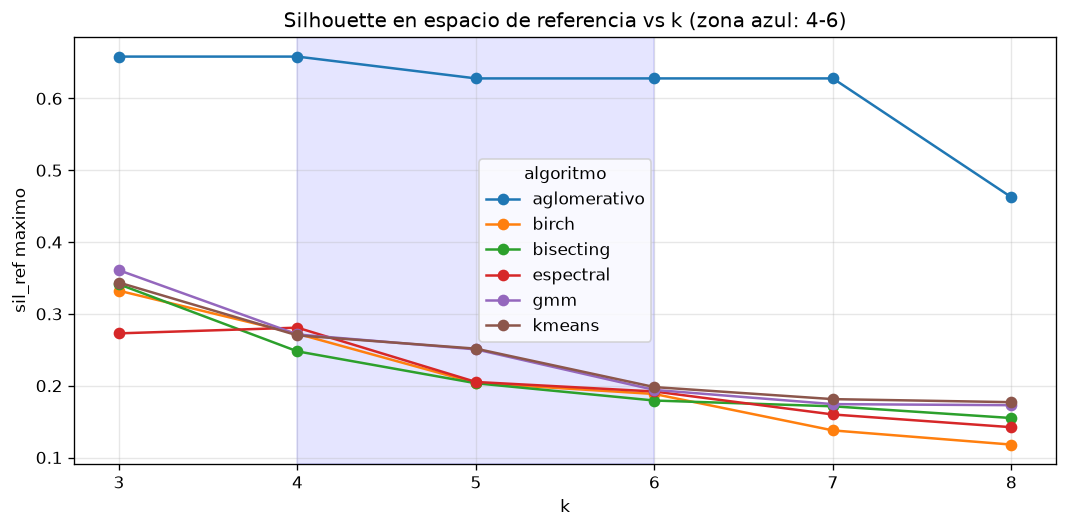

In [18]:
curvas = res.dropna(subset=["k"]).groupby(["algoritmo", "k"])["sil_ref"].max().unstack(0)

fig, ax = plt.subplots(figsize=(9, 4.5))
curvas.plot(ax=ax, marker="o")
ax.axvspan(K_VALIDO.start, K_VALIDO.stop - 1, alpha=0.1, color="blue")
ax.set_xlabel("k")
ax.set_ylabel("sil_ref maximo")
ax.set_title("Silhouette en espacio de referencia vs k (zona azul: 4-6)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.5 Efecto de agregar demografia

Comparacion de metricas promedio entre configuraciones validas, por grupo de variables.
Si la demografia sube `sil` pero baja `sil_ref` y `r2_prom`, los perfiles se estan
separando por edad o sexo y no por conducta.

In [19]:
grupo = res["conjunto"].str[0].map(
    {"A": "conducta", "B": "conducta", "C": "conducta", "D": "conducta",
     "E": "conducta + demo", "F": "conducta + demo", "G": "conducta + demo",
     "H": "conducta + demo", "I": "solo demo"}
)
res["grupo"] = grupo
(res[validas].groupby("grupo")[["sil", "sil_ref", "r2_prom", "v_edad", "v_sexo"]]
 .mean().round(3))

,sil,sil_ref,r2_prom,v_edad,v_sexo
grupo,,,,,
conducta,0.198,0.117,0.692,0.280,0.275
conducta + demo,0.154,-0.004,0.362,0.238,0.572
solo demo,0.347,-0.054,0.097,0.107,0.206


### 5.6 Top 20 configuraciones validas

In [20]:
COLS_TABLA = ["id", "conjunto", "prep", "algoritmo", "params", "k_eff", "min_pct",
              "sil", "sil_ref", "r2_prom", "db", "v_edad", "v_sexo", "score"]
res[validas].nlargest(20, "score")[COLS_TABLA].round(3)

,id,conjunto,prep,algoritmo,params,k_eff,min_pct,sil,sil_ref,r2_prom,db,v_edad,v_sexo,score
564,564,C_trayectoria,estandar_pca,gmm,"k=4, cov=spherical",4,14.59,0.305,0.204,0.895,1.007,0.363,0.331,0.940
558,558,C_trayectoria,estandar_pca,bisecting,k=4,4,17.72,0.299,0.199,0.897,1.053,0.363,0.331,0.937
557,557,C_trayectoria,estandar_pca,kmeans,k=4,4,17.55,0.299,0.199,0.897,1.054,0.364,0.333,0.935
563,563,C_trayectoria,estandar_pca,gmm,"k=4, cov=tied",4,11.93,0.302,0.205,0.883,0.978,0.357,0.326,0.932
571,571,C_trayectoria,estandar_pca,espectral,k=5,5,8.64,0.268,0.168,0.924,1.084,0.317,0.330,0.919
562,562,C_trayectoria,estandar_pca,gmm,"k=4, cov=diag",4,15.93,0.296,0.197,0.891,1.040,0.363,0.333,0.917
569,569,C_trayectoria,estandar_pca,bisecting,k=5,5,15.74,0.276,0.179,0.897,1.127,0.315,0.334,0.914
568,568,C_trayectoria,estandar_pca,kmeans,k=5,5,15.68,0.285,0.183,0.893,1.120,0.313,0.333,0.914
579,579,C_trayectoria,estandar_pca,kmeans,k=6,6,11.18,0.268,0.163,0.924,1.131,0.286,0.333,0.913
586,586,C_trayectoria,estandar_pca,gmm,"k=6, cov=spherical",6,10.13,0.262,0.159,0.925,1.077,0.286,0.332,0.907


## 6. Estabilidad (etapa 2)

Candidatas: las 15 mejores por puntaje mas la mejor de cada algoritmo. Cada una se
reajusta con 5 muestras de ajuste nuevas (y semillas distintas) y se compara contra sus
etiquetas originales en la muestra eval con el indice de Rand ajustado (ARI).
Un ARI cercano a 1 indica que los perfiles no dependen de la muestra.

In [21]:
mejores_algo = res[validas].loc[res[validas].groupby("algoritmo")["score"].idxmax()]
candidatas = pd.concat([res[validas].nlargest(N_CANDIDATOS, "score"), mejores_algo])
candidatas = candidatas.drop_duplicates("id").sort_values("score", ascending=False)
print(f"Candidatas: {len(candidatas)}")

Candidatas: 18


In [22]:
estabilidad = []
for cid in tqdm(candidatas["id"], desc="bootstrap"):
    conjunto, prep, algo, prm = CONFIGS[cid]
    aris = []
    for b in range(N_BOOT):
        seed = 1000 + b
        idx_f, _ = muestra_ajuste(seed)
        tr, X = preparar(conjunto, prep, idx_f)
        Z_f = tr.transform(X[idx_f])
        modelo, _ = ajustar(algo, prm, Z_f, Z_f[:N_SUB], seed, {})
        aris.append(adjusted_rand_score(ETIQUETAS[cid], modelo.predict(tr.transform(X[idx_eval]))))
    estabilidad.append({"id": cid, "ari_media": np.mean(aris), "ari_min": np.min(aris)})

candidatas = candidatas.merge(pd.DataFrame(estabilidad), on="id")
candidatas[COLS_TABLA + ["ari_media", "ari_min"]].round(3)

bootstrap:   0%|          | 0/18 [00:00<?, ?it/s]

,id,conjunto,prep,algoritmo,params,k_eff,min_pct,sil,sil_ref,r2_prom,db,v_edad,v_sexo,score,ari_media,ari_min
0,564,C_trayectoria,estandar_pca,gmm,"k=4, cov=spherical",4,14.59,0.305,0.204,0.895,1.007,0.363,0.331,0.940,0.927,0.843
1,558,C_trayectoria,estandar_pca,bisecting,k=4,4,17.72,0.299,0.199,0.897,1.053,0.363,0.331,0.937,0.984,0.975
2,557,C_trayectoria,estandar_pca,kmeans,k=4,4,17.55,0.299,0.199,0.897,1.054,0.364,0.333,0.935,0.964,0.921
3,563,C_trayectoria,estandar_pca,gmm,"k=4, cov=tied",4,11.93,0.302,0.205,0.883,0.978,0.357,0.326,0.932,0.944,0.902
4,571,C_trayectoria,estandar_pca,espectral,k=5,5,8.64,0.268,0.168,0.924,1.084,0.317,0.330,0.919,0.741,0.421
5,562,C_trayectoria,estandar_pca,gmm,"k=4, cov=diag",4,15.93,0.296,0.197,0.891,1.040,0.363,0.333,0.917,0.609,0.401
6,569,C_trayectoria,estandar_pca,bisecting,k=5,5,15.74,0.276,0.179,0.897,1.127,0.315,0.334,0.914,0.982,0.973
7,568,C_trayectoria,estandar_pca,kmeans,k=5,5,15.68,0.285,0.183,0.893,1.120,0.313,0.333,0.914,0.837,0.754
8,579,C_trayectoria,estandar_pca,kmeans,k=6,6,11.18,0.268,0.163,0.924,1.131,0.286,0.333,0.913,0.835,0.656
9,586,C_trayectoria,estandar_pca,gmm,"k=6, cov=spherical",6,10.13,0.262,0.159,0.925,1.077,0.286,0.332,0.907,0.834,0.676


### 6.1 Finalistas

Se descartan las candidatas con ARI medio menor a 0.8. De las estables, pasan las 3 de
mayor puntaje.

In [23]:
estables = candidatas[candidatas["ari_media"] >= ARI_ESTABLE]
if len(estables) == 0:
    print("Ninguna candidata supera el umbral de ARI; se usan las mas estables.")
    estables = candidatas.nlargest(N_FINALISTAS, "ari_media")
finalistas = estables.nlargest(N_FINALISTAS, "score")
print(f"Estables: {len(estables)} de {len(candidatas)}")
finalistas[COLS_TABLA + ["ari_media"]].round(3)

Estables: 12 de 18


,id,conjunto,prep,algoritmo,params,k_eff,min_pct,sil,sil_ref,r2_prom,db,v_edad,v_sexo,score,ari_media
0,564,C_trayectoria,estandar_pca,gmm,"k=4, cov=spherical",4,14.59,0.305,0.204,0.895,1.007,0.363,0.331,0.940,0.927
1,558,C_trayectoria,estandar_pca,bisecting,k=4,4,17.72,0.299,0.199,0.897,1.053,0.363,0.331,0.937,0.984
2,557,C_trayectoria,estandar_pca,kmeans,k=4,4,17.55,0.299,0.199,0.897,1.054,0.364,0.333,0.935,0.964


## 7. Afinacion y modelo final (etapa 3)

Las finalistas se reajustan con mas datos y mas inicializaciones:

- KMeans y BisectingKMeans: todas las celdas con `sample_weight` y `n_init=20`.
- GMM: muestra ponderada de 200k con `n_init=5`.
- Birch, aglomerativo, espectral y HDBSCAN: muestra sub y asignacion a todas las celdas.

Se agrega como referencia el modelo del notebook 04 (A_base, estandar, KMeans k=4).

In [24]:
def ajustar_final(conjunto, prep, algo, prm):
    tr, X = preparar(conjunto, prep, idx_fit)
    Z_all = tr.transform(X)
    if algo in ("kmeans", "bisecting"):
        modelo, _ = ajustar(algo, prm, Z_all, None, RANDOM_STATE, {},
                            w=celdas["peso"].to_numpy(), n_init=20)
    elif algo == "gmm":
        idx_big, _ = muestra_ajuste(RANDOM_STATE, n=N_FINAL)
        modelo, _ = ajustar(algo, prm, Z_all[idx_big], None, RANDOM_STATE, {}, n_init=5)
    else:
        modelo, _ = ajustar(algo, prm, None, Z_all[idx_sub], RANDOM_STATE, {})
    return modelo.predict(Z_all), Z_all


modelos_finales = {"base_04": ("A_base", "estandar", "kmeans", {"k": 4})}
for i, r in enumerate(finalistas.itertuples(), start=1):
    modelos_finales[f"candidato_{i}"] = CONFIGS[r.id]

etiquetas_finales, metricas_finales = {}, []
for nombre, (conjunto, prep, algo, prm) in tqdm(modelos_finales.items(), desc="modelos finales"):
    labels, Z_all = ajustar_final(conjunto, prep, algo, prm)
    etiquetas_finales[nombre] = labels
    metricas_finales.append({
        "modelo": nombre, "conjunto": conjunto, "prep": prep, "algoritmo": algo,
        "params": ", ".join(f"{k}={v}" for k, v in prm.items()),
        **evaluar(labels[idx_eval], Z_all[idx_eval]),
    })

metricas_finales = pd.DataFrame(metricas_finales)
metricas_finales.round(3)

modelos finales:   0%|          | 0/4 [00:00<?, ?it/s]

,modelo,conjunto,prep,algoritmo,params,k_eff,pct_ruido,min_pct,sil,db,ch,sil_ref,r2_prom,v_edad,v_sexo
0,base_04,A_base,estandar,kmeans,k=4,4,0.0,18.21,0.261,1.144,4497.743,0.128,0.574,0.284,0.257
1,candidato_1,C_trayectoria,estandar_pca,gmm,"k=4, cov=spherical",4,0.0,14.52,0.305,1.006,10041.155,0.204,0.894,0.363,0.331
2,candidato_2,C_trayectoria,estandar_pca,bisecting,k=4,4,0.0,17.23,0.299,1.053,10137.327,0.199,0.897,0.364,0.335
3,candidato_3,C_trayectoria,estandar_pca,kmeans,k=4,4,0.0,17.74,0.299,1.055,10139.017,0.198,0.897,0.364,0.331


### 7.1 Coincidencia entre modelos

ARI entre las particiones finales, medido sobre la muestra eval. Valores bajos frente a
`base_04` indican que el candidato propone perfiles distintos a los actuales.

In [25]:
nombres = list(etiquetas_finales)
ari = pd.DataFrame(
    [[adjusted_rand_score(etiquetas_finales[a][idx_eval], etiquetas_finales[b][idx_eval])
      for b in nombres] for a in nombres],
    index=nombres, columns=nombres,
)
ari.round(3)

,base_04,candidato_1,candidato_2,candidato_3
base_04,1.000,0.203,0.215,0.216
candidato_1,0.203,1.000,0.847,0.825
candidato_2,0.215,0.847,1.000,0.953
candidato_3,0.216,0.825,0.953,1.000


### 7.2 Perfiles de cada modelo

Resumen ponderado por peso. Los perfiles se ordenan por promedio de participacion.
La caracterizacion detallada y los nombres se hacen despues, una vez elegido el modelo.

In [26]:
def resumen_perfiles(labels):
    df = celdas.assign(perfil=labels)
    df = df[df["perfil"] >= 0]
    filas = []
    for p, dp in df.groupby("perfil"):
        w = dp["peso"]
        edad = dp.groupby("GRUPO_EDAD")["peso"].sum()
        filas.append({
            "pct_pob": w.sum() / df["peso"].sum() * 100,
            "promedio": np.average(dp["promedio"], weights=w),
            "brecha_pres": np.average(dp["brecha_pres"], weights=w),
            "tendencia": np.average(dp["tendencia"], weights=w),
            "P_PJ2025": np.average(dp["P_PJ2025"], weights=w),
            "pct_mujer": np.average(dp["MUJER"], weights=w) * 100,
            "pct_rural_mixta": np.average(dp["TIPOSEC_ORD"] > 0, weights=w) * 100,
            "edad_dominante": edad.idxmax(),
        })
    return pd.DataFrame(filas).sort_values("promedio").reset_index(drop=True).round(1)


for nombre, labels in etiquetas_finales.items():
    conjunto, prep, algo, prm = modelos_finales[nombre]
    print(f"\n{nombre}: {conjunto} | {prep} | {algo} {prm}")
    print(resumen_perfiles(labels).to_string())


base_04: A_base | estandar | kmeans {'k': 4}
   pct_pob  promedio  brecha_pres  tendencia  P_PJ2025  pct_mujer  pct_rural_mixta edad_dominante
0     27.4      42.0         15.3        1.2      11.7       34.8             23.4          30-39
1     19.3      54.4          4.8       -1.7      10.6       46.1             44.7          30-39
2     25.4      56.9         22.0        4.4      14.9       62.0             20.4          30-39
3     27.9      69.4         10.0        1.9      14.6       65.1             35.8          50-59

candidato_1: C_trayectoria | estandar_pca | gmm {'k': 4, 'cov': 'spherical'}
   pct_pob  promedio  brecha_pres  tendencia  P_PJ2025  pct_mujer  pct_rural_mixta edad_dominante
0     14.7      34.4         13.0        0.8      10.5       20.3             30.0          25-29
1     32.3      48.3         15.4        1.5      12.6       46.0             25.0          30-39
2     35.0      61.8         13.8        1.9      13.5       62.7             28.7          

   pct_pob  promedio  brecha_pres  tendencia  P_PJ2025  pct_mujer  pct_rural_mixta edad_dominante
0     17.8      35.7         13.4        0.9      10.8       22.2             29.1          30-39
1     30.4      49.3         15.5        1.6      12.7       47.9             25.0          30-39
2     31.5      61.5         13.8        1.9      13.5       62.5             28.6          40-49
3     20.3      74.3         10.2        1.9      15.3       69.7             41.2          60-69


## 8. Exportacion

No se sobrescribe nada del notebook 04. Se guardan los resultados de la malla,
la estabilidad de las candidatas y las etiquetas de los modelos finales por celda.

In [27]:
res.drop(columns=["grupo"]).to_csv(DIR_PREPROCESSED / "experimentos_clustering.csv", index=False)
candidatas.to_csv(DIR_PREPROCESSED / "experimentos_estabilidad.csv", index=False)
metricas_finales.to_csv(DIR_PREPROCESSED / "experimentos_finalistas.csv", index=False)

salida = celdas[["EDOCVE", "SECCION", "SEXO", "GRUPO_EDAD", "peso"]].copy()
for nombre, labels in etiquetas_finales.items():
    salida[nombre] = labels.astype("int8")
salida.to_parquet(DIR_PREPROCESSED / "celdas_perfiles_candidatos.parquet", index=False)

for f in ["experimentos_clustering.csv", "experimentos_estabilidad.csv",
          "experimentos_finalistas.csv", "celdas_perfiles_candidatos.parquet"]:
    print(f"{f}: {(DIR_PREPROCESSED / f).stat().st_size / 1024:.0f} KB")

experimentos_clustering.csv: 483 KB
experimentos_estabilidad.csv: 6 KB
experimentos_finalistas.csv: 1 KB
celdas_perfiles_candidatos.parquet: 1885 KB
